# Signature-Based Deep Hedging

**Objective:** learn a self-financing strategy that replicates a path-dependent terminal payoff.

1. Simulate asset prices.
2. Encode the observed path using a truncated, time-augmented signature.
3. Fit a linear signature strategy by L2 regression.
4. Train a nonlinear neural strategy on **256 freshly simulated paths per epoch**.
5. Compare both strategies on the same independent test set.

The claim is a put on a geometric mean of window averages, settled at maturity. Early exercise is outside the scope of this experiment.

In [1]:
import copy
import math
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

# Dependencies: numpy, torch, matplotlib
torch.set_num_threads(2)
torch.manual_seed(7)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

## 1. Market Model: Physical and Risk-Neutral Dynamics

Under the physical measure $\mathbb P$, asset prices have annual drift $\mu$:

$$S_{n+1}^i=S_n^i\exp\left((\mu-\tfrac12\sigma^2)\Delta t+\sigma\sqrt{\Delta t}\,Z_n^i\right),\qquad S_0^i=1.$$

Under the risk-neutral measure $\mathbb Q$, replace $\mu$ with the risk-free rate $r$. Dividends are zero, and the bank account grows as $B_t=e^{rt}$.

| Purpose | Measure | Asset drift |
|---|---|---|
| Feature calibration, training, validation and testing | $\mathbb P$ | $\mu=8\%$ |
| Initial option price estimation | $\mathbb Q$ | $r=3\%$ |

Rates are annualized and continuously compounded; time is measured in years. Trading is frictionless. Discounted asset prices are martingales under $\mathbb Q$, not generally under $\mathbb P$.

The initial capital is estimated independently and remains fixed during training. Validation and test samples are independent and fixed. **Training generates 256 new paths under $\mathbb P$ in every epoch.**


14 features; approximately 0.02 GB for feature arrays.


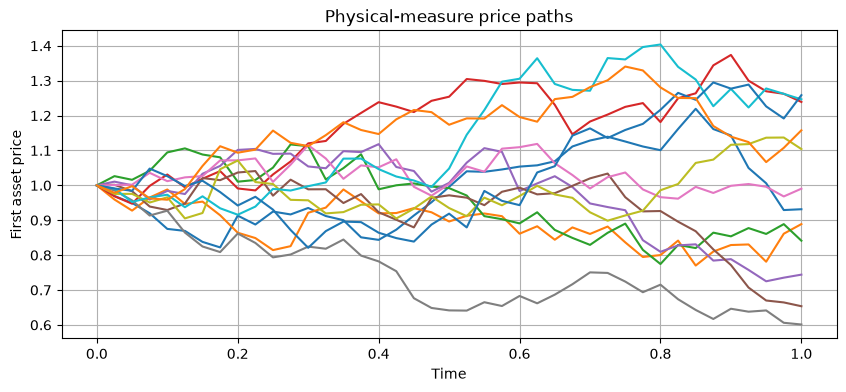

In [2]:
n_calibration, n_val, n_test = 2048, 2048, 4096
paths_per_epoch, epochs = 256, 2000
n_pricing = 100_000
n_steps, n_windows, d = 40, 10, 1
T, sigma, rho, strike = 1.0, 0.25, 0.3, 1.0
mu, r = 0.08, 0.03
depth = 3
claim_type = 'geometric_put'  # Alternative: 'asian_call'
weights = torch.full((d,), 1.0 / d)

assert n_steps % n_windows == 0, 'Each window must contain an integer number of steps.'
assert d == 1 or -1 / (d - 1) < rho < 1
feature_dim = sum((d + 1)**k for k in range(1, depth + 1))
memory_gb = (n_calibration + paths_per_epoch + n_val + n_test) * n_steps * feature_dim * 4 / 1e9
print(f'{feature_dim} features; approximately {memory_gb:.2f} GB for feature arrays.')
assert memory_gb < 2, 'Reduce depth, asset count or sample sizes: signature size grows exponentially.'

def simulate_paths(n_paths, seed, drift):
    """Return prices [path, time, asset], including time zero."""
    generator = torch.Generator().manual_seed(seed)
    corr = (1 - rho) * torch.eye(d) + rho * torch.ones(d, d)
    chol = torch.linalg.cholesky(corr)
    z = torch.randn(n_paths, n_steps, d, generator=generator) @ chol.T
    dt = T / n_steps
    log_returns = (drift - 0.5 * sigma**2) * dt + sigma * math.sqrt(dt) * z
    log_prices = torch.cat([torch.zeros(n_paths, 1, d), log_returns.cumsum(1)], dim=1)
    return log_prices.exp()

S_calibration = simulate_paths(n_calibration, 10, drift=mu)
S_val = simulate_paths(n_val, 20, drift=mu)
S_test = simulate_paths(n_test, 30, drift=mu)
times = torch.linspace(0, T, n_steps + 1)

plt.plot(times, S_calibration[:12, :, 0].T)
plt.xlabel('Time'); plt.ylabel('First asset price'); plt.title('Physical-measure price paths')
plt.show()

## 2. Path-Dependent Claim

Split $[0,T]$ into $M$ equal windows. For each asset, compute the arithmetic average in each window, then the geometric mean across windows:

$$A_j^i=\frac{1}{u_{j+1}-u_j}\int_{u_j}^{u_{j+1}}S_t^i\,dt,
\qquad I_i=\exp\left(\frac1M\sum_{j=0}^{M-1}\log A_j^i\right).$$

The terminal claim is

$$H=\left(K-\sum_{i=1}^d w_i I_i\right)^+.$$

Trapezoidal integration is exact for the piecewise-linear price interpolation and approximates the continuous-time integral. The same function also supports an arithmetic Asian call.

### Fixed Initial Capital

Estimate the risk-neutral value of the discretized claim using 100,000 independent pricing paths with drift $r$, discounting the payoff to time zero:

$$\widehat p\approx\mathbb E^{\mathbb Q}[e^{-rT}H],\qquad\widehat p=\frac{e^{-rT}}{N_{\mathrm{price}}}\sum_{j=1}^{N_{\mathrm{price}}}H^{(j)}.$$

This estimate is fixed before training. Pricing paths are separate from feature calibration, training, validation and test paths. The Monte Carlo confidence interval measures sampling uncertainty, not time-discretization error.


In [3]:
def terminal_claim(S, kind=claim_type):
    """Return one terminal payoff per path."""
    midpoint_prices = 0.5 * (S[:, :-1] + S[:, 1:])
    if kind == 'geometric_put':
        steps_per_window = n_steps // n_windows
        window_means = midpoint_prices.reshape(-1, n_windows, steps_per_window, d).mean(2)
        geometric_means = window_means.log().mean(1).exp()
        return (strike - geometric_means @ weights).clamp_min(0)
    if kind == 'asian_call':
        arithmetic_means = midpoint_prices.mean(1)
        return (arithmetic_means @ weights - strike).clamp_min(0)
    raise ValueError('Unknown claim type')

def estimate_price(n_paths, batch_size=4096):
    """Estimate the claim price and its Monte Carlo standard error."""
    payoffs = []
    for batch, start in enumerate(range(0, n_paths, batch_size)):
        size = min(batch_size, n_paths - start)
        S = simulate_paths(size, seed=1_000_000 + batch, drift=r)
        payoffs.append(terminal_claim(S))
    H = math.exp(-r * T) * torch.cat(payoffs).double()
    return H.mean().item(), (H.std() / math.sqrt(n_paths)).item()

initial_capital, price_se = estimate_price(n_pricing)
H_val = terminal_claim(S_val)
H_test = terminal_claim(S_test)
print(f'Fixed initial capital (risk-neutral price): {initial_capital:.5f}')
print(f'Pricing Monte Carlo SE: {price_se:.5f}')
print(f'Approximate 95% pricing CI: [{initial_capital - 1.96*price_se:.5f}, '
      f'{initial_capital + 1.96*price_se:.5f}]')


Fixed initial capital (risk-neutral price): 0.05119
Pricing Monte Carlo SE: 0.00023
Approximate 95% pricing CI: [0.05074, 0.05164]


## 3. Time-Augmented Signature

Interpolate the augmented observations linearly:

$$Z_t=(t/T,S_t^1/S_0^1-1,\ldots,S_t^d/S_0^d-1).$$

For a segment with increment $v$, the signature levels are

$$E^{(0)}=1,\qquad E^{(k)}=\frac{v^{\otimes k}}{k!}.$$

Chen's identity updates the signature when a new segment is added:

$$A_{\mathrm{new}}^{(k)}=\sum_{j=0}^k A_{\mathrm{old}}^{(j)}\otimes E^{(k-j)}.$$

We retain levels $1,\ldots,m$, giving $\sum_{k=1}^m(d+1)^k$ features. At time $t_n$, features use only observations up to $t_n$. Time augmentation encodes temporal information; truncation compresses the path and may lose information.

The construction follows Example 1 and Definitions 2–4 of Gu et al., *Transportation Marketplace Rate Forecast Using Signature Transform*, [arXiv:2401.04857v3](https://arxiv.org/abs/2401.04857v3). The financial experiment is separate from that paper's forecasting application.

In [4]:
def tensor_product(a, b):
    """Flattened tensor product for each path."""
    return (a.unsqueeze(-1) * b.unsqueeze(-2)).flatten(1)

def prefix_signatures(Z, depth):
    """Prefix signatures before each price increment: [batch, steps, features]."""
    batch, nodes, channels = Z.shape
    levels = [torch.ones(batch, 1, dtype=Z.dtype)]
    levels += [torch.zeros(batch, channels**k, dtype=Z.dtype) for k in range(1, depth + 1)]
    prefixes = []
    for n in range(nodes - 1):
        # Record the prefix at n before adding the segment n -> n+1.
        prefixes.append(torch.cat(levels[1:], dim=1))
        increment = Z[:, n + 1] - Z[:, n]
        segment = [torch.ones(batch, 1, dtype=Z.dtype)]
        for k in range(1, depth + 1):
            segment.append(tensor_product(segment[-1], increment) / k)
        old = levels
        levels = [sum(tensor_product(old[j], segment[k-j]) for j in range(k+1))
                  for k in range(depth + 1)]
    return torch.stack(prefixes, dim=1)

def make_features(S):
    time_channel = times.reshape(1, -1, 1).expand(S.shape[0], -1, -1) / T
    relative_prices = S / S[:, :1] - 1
    augmented_path = torch.cat([time_channel, relative_prices], dim=-1)
    return prefix_signatures(augmented_path, depth)

# Fit scaling once on an independent calibration sample.
F_calibration = make_features(S_calibration)
feature_mean = F_calibration.mean(dim=(0, 1), keepdim=True)
feature_scale = F_calibration.std(dim=(0, 1), keepdim=True).clamp_min(1e-6)

def scaled_features(S):
    return (make_features(S) - feature_mean) / feature_scale

F_val = scaled_features(S_val)
F_test = scaled_features(S_test)
print('Validation feature shape:', tuple(F_val.shape))

Validation feature shape: (2048, 40, 14)


### Consistency Checks

Verify the straight-line signature formula and causality: changing future prices must leave earlier features unchanged.

In [11]:
v = torch.tensor([[0.4, -0.2]])
line = torch.stack([torch.zeros_like(v), v / 2, v, v], dim=1)
actual = prefix_signatures(line, 3)[:, -1]
expected = torch.cat([v, tensor_product(v, v) / 2,
                      tensor_product(tensor_product(v, v), v) / 6], dim=1)
torch.testing.assert_close(actual, expected)

cut = n_steps // 2
changed = S_calibration[:3].clone()
changed[:, cut + 1:] *= 1.2
torch.testing.assert_close(make_features(changed)[:, :cut + 1],
                           make_features(S_calibration[:3])[:, :cut + 1])
print('Checks passed: Chen identity and causality.')

Checks passed: Chen identity and causality.


## 4. Self-Financing Portfolio and L2 Objective

At time $t_n$, choose holdings $h_n\in\mathbb R^d$ using only the observed path. The initial capital $\widehat p$ is fixed at the independent risk-neutral Monte Carlo price.

With cash balance $b_n=V_n-h_n\cdot S_n$ earning interest at rate $r$,

$$V_{n+1}=h_n\cdot S_{n+1}+(V_n-h_n\cdot S_n)e^{r\Delta t}.$$

Using discounted prices $\widetilde S_n=e^{-rt_n}S_n$ gives

$$V_n=e^{rt_n}\left(\widehat p+\sum_{k=0}^{n-1}h_k\cdot\Delta\widetilde S_k\right).$$

Both models minimize terminal mean squared error under the physical measure:

$$\mathcal L(h)=\mathbb E^{\mathbb P}[(V_N-H)^2].$$

Since $T$ and $r$ are fixed, minimizing this loss is equivalent to minimizing

$$\mathbb E^{\mathbb P}\left[\left(\sum_{n=0}^{N-1}h_n\cdot\Delta\widetilde S_n-Y\right)^2\right],\qquad Y=e^{-rT}H-\widehat p.$$

This objective fits terminal trading gains, rather than regressing the claim directly on its full-path signature. Future increments enter the training loss, never the features used to choose a position.


In [ ]:
def wealth_from_holdings(h, S, capital):
    """Self-financing wealth, including interest on the cash balance."""
    
    bank_account = torch.exp(r * times).reshape(1, -1)
    discounted_S = S / bank_account.unsqueeze(-1)
    gains = (h * (discounted_S[:, 1:] - discounted_S[:, :-1])).sum(dim=-1)
    initial = torch.as_tensor(capital, dtype=S.dtype).expand(S.shape[0], 1)
    
    discounted_V = torch.cat([initial, initial + gains.cumsum(dim=1)], dim=1)
    return bank_account * discounted_V

## 5. Linear Signature Hedging by Least Squares

Let $F_n$ be the standardized signature up to degree $m$, and include a constant coordinate:

$$\phi_n=(1,F_n)\in\mathbb R^q,\qquad h_n=C^\top\phi_n,\qquad C\in\mathbb R^{q\times d}.$$

The coefficients are shared across trading dates; time is encoded in the signature. Standardization and the intercept preserve the class of affine functions of the truncated signature.

For each simulated path $j$, construct the regression row

$$A_{j,(a,i)}=\sum_{n=0}^{N-1}\phi_{n,a}^{(j)}\Delta\widetilde S_n^{i,(j)},\qquad y_j=e^{-rT}H^{(j)}-\widehat p.$$

Then terminal discounted gains equal $A_j\operatorname{vec}(C)$, so the empirical hedging problem is ordinary least squares:

$$\widehat C=\arg\min_C\frac1J\|A\operatorname{vec}(C)-y\|_2^2.$$

An SVD-based solver handles dependent columns without inverting $A^\top A$. No regularization is added. We generate the same 2,000 batches of 256 paths used by the neural model, with identical seeds, and retain only the regression rows and targets.

### Fixed Degree: Projection, Not Universal Approximation

At fixed $m$, the attainable discounted gains form a finite-dimensional linear subspace of $L^2(\mathbb P)$. The population optimum is the **orthogonal projection of $Y$ onto that subspace**. The sample least-squares solution estimates this optimum; it is not necessarily the population minimizer. Coefficients need not be unique when features are linearly dependent.

“Best estimator” here means best within this specific shared-coefficient linear strategy class, under squared hedging error. It does not mean the best among all path-dependent strategies, nor does it assert exact replication.

Signature universality concerns a sufficiently rich family with increasing degree and appropriate assumptions. A fixed truncation generally does not form the full shuffle algebra and does not guarantee universal approximation. A neural network can learn nonlinear functions of the same finite features, but cannot recover information lost through truncation. Density of path functionals also does not, by itself, establish density of admissible trading strategies.

In [7]:
def add_constant(features):
    return torch.cat([torch.ones_like(features[..., :1]), features], dim=-1)

def regression_batch(S):
    phi = add_constant(scaled_features(S)).double()
    discounted_S = S.double() * torch.exp(-r * times.double()).reshape(1, -1, 1)
    increments = discounted_S[:, 1:] - discounted_S[:, :-1]
    A = torch.einsum('bnq,bni->bqi', phi, increments).flatten(1)
    y = math.exp(-r * T) * terminal_claim(S).double() - initial_capital
    return A, y

def fit_linear_signature(n_batches=epochs, batch_size=paths_per_epoch):
    """Fit empirical L2 hedging on the same simulated paths as the NN."""
    design_gb = n_batches * batch_size * (feature_dim + 1) * d * 8 / 1e9
    assert design_gb < 1, 'Reduce the sample size or signature dimension.'
    rows, targets = [], []
    for batch in range(n_batches):
        S = simulate_paths(batch_size, seed=10_000 + batch, drift=mu)
        A, y = regression_batch(S)
        rows.append(A)
        targets.append(y)
    A, y = torch.cat(rows), torch.cat(targets)
    fit = torch.linalg.lstsq(A, y, driver='gelsd', rcond=1e-10)
    coefficients = fit.solution.reshape(feature_dim + 1, d).float()
    print(f'Least squares: {len(y):,} paths, {A.shape[1]} coefficients, rank {fit.rank.item()}')
    return coefficients

def linear_portfolio(coefficients, features, S):
    h = add_constant(features) @ coefficients
    return wealth_from_holdings(h, S, initial_capital), h

linear_coefficients = fit_linear_signature()
with torch.no_grad():
    V_linear_val, _ = linear_portfolio(linear_coefficients, F_val, S_val)
    print(f'Linear validation MSE: {(V_linear_val[:, -1] - H_val).square().mean():.6f}')

# The regression prediction must equal the discounted trading gain.
A_check, _ = regression_batch(S_val[:4])
V_check, _ = linear_portfolio(linear_coefficients, F_val[:4], S_val[:4])
expected_gain = A_check @ linear_coefficients.double().flatten()
actual_gain = math.exp(-r * T) * V_check[:, -1].double() - initial_capital
torch.testing.assert_close(actual_gain, expected_gain, rtol=1e-4, atol=1e-6)
print('Regression design and portfolio gains agree.')

Least squares: 512,000 paths, 15 coefficients, rank 15
Linear validation MSE: 0.000264
Regression design and portfolio gains agree.


## 6. Neural Signature Hedging

Replace the linear map with a nonlinear neural network:

$$h_n=f_\theta(F_n).$$

The network has two hidden layers of 32 units with Tanh activations and a linear output. Holdings may be negative. The same network is shared across dates, and time is already encoded in the signature.

The initial capital, features, simulated training paths and terminal L2 objective are the same as for linear regression. Only the representation of the trading rule and its optimization change. Adam need not find the global optimum of the neural objective.

In [ ]:
x

def portfolio(model, features, S):
    """V includes V_0; h[:, n] is held over the interval n -> n+1."""
    h = model(features)
    V = wealth_from_holdings(h, S, model.capital)
    return V, h

def hedging_loss(model, features, S, H):
    V, _ = portfolio(model, features, S)
    return (V[:, -1] - H).square().mean()

model = HedgeNet(feature_dim, d, initial_capital)
assert "capital" not in dict(model.named_parameters())

# Check equivalence with the stock-and-bank-account recursion.
with torch.no_grad():
    V_check, h_check = portfolio(model, F_val[:2], S_val[:2])
    next_wealth = ((h_check * S_val[:2, 1:]).sum(-1)
                  + (V_check[:, :-1] - (h_check * S_val[:2, :-1]).sum(-1))
                  * math.exp(r * T / n_steps))
    torch.testing.assert_close(V_check[:, 1:], next_wealth)
print('Self-financing recursion check passed.')


Self-financing recursion check passed.


### Training on Fresh Simulations

Every epoch generates **256 new physical-measure paths**, computes their payoffs and signature features, and performs **one gradient update**. No fixed training set is reused.

We run 2,000 epochs (512,000 simulated training paths in total). Distinct seeds produce reproducible fresh samples. Feature scaling remains fixed throughout training.

Validation is evaluated every 50 epochs and selects the best model. The test set is reserved for final evaluation. Training loss is measured on the current batch before its update; validation loss is measured after the update. The training curve is therefore naturally noisy.

Epoch  250 | fresh-batch MSE 0.000138 | validation 0.000131
Epoch  500 | fresh-batch MSE 0.000095 | validation 0.000102
Epoch  750 | fresh-batch MSE 0.000090 | validation 0.000097
Epoch 1000 | fresh-batch MSE 0.000097 | validation 0.000096
Epoch 1250 | fresh-batch MSE 0.000095 | validation 0.000100
Epoch 1500 | fresh-batch MSE 0.000090 | validation 0.000095
Epoch 1750 | fresh-batch MSE 0.000100 | validation 0.000094
Epoch 2000 | fresh-batch MSE 0.000118 | validation 0.000095


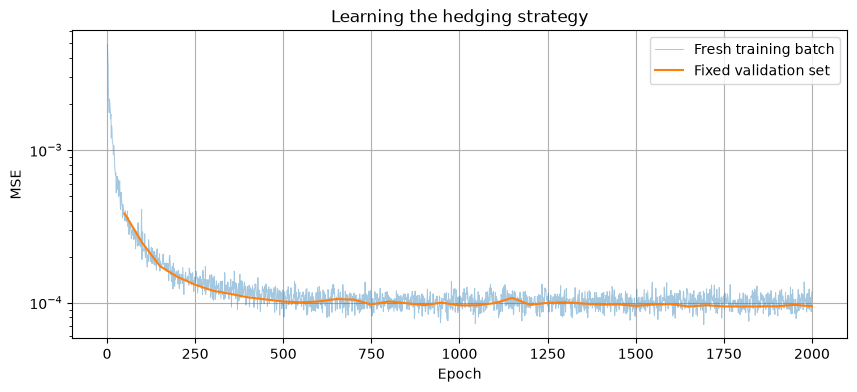

In [9]:
def train_model(model, epochs=epochs, batch_size=paths_per_epoch, learning_rate=0.002):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = {'train': [], 'validation': [], 'validation_epoch': []}
    best_loss, best_state = float('inf'), None
    for epoch in range(epochs):
        # One new Monte Carlo batch and one optimizer step per epoch.
        S = simulate_paths(batch_size, seed=10_000 + epoch, drift=mu)
        H = terminal_claim(S)
        F = scaled_features(S)

        model.train()
        optimizer.zero_grad()
        loss = hedging_loss(model, F, S, H)
        loss.backward()
        optimizer.step()
        history['train'].append(loss.item())

        if (epoch + 1) % 50 == 0 or epoch + 1 == epochs:
            model.eval()
            with torch.no_grad():
                val_loss = hedging_loss(model, F_val, S_val, H_val).item()
            history['validation'].append(val_loss)
            history['validation_epoch'].append(epoch + 1)
            if val_loss < best_loss:
                best_loss = val_loss
                best_state = copy.deepcopy(model.state_dict())
            if (epoch + 1) % 250 == 0 or epoch + 1 == epochs:
                print(f'Epoch {epoch+1:4d} | fresh-batch MSE {loss.item():.6f} | validation {val_loss:.6f}')

    model.load_state_dict(best_state)
    model.eval()
    return history

capital_before_training = model.capital.clone()
history = train_model(model)
torch.testing.assert_close(model.capital, capital_before_training, rtol=0, atol=0)
plt.semilogy(np.arange(1, len(history['train']) + 1), history['train'],
             alpha=0.4, linewidth=0.7, label='Fresh training batch')
plt.semilogy(history['validation_epoch'], history['validation'], label='Fixed validation set')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.legend()
plt.title('Learning the hedging strategy'); plt.show()

## 7. Out-of-Sample Results

Compare the linear and neural strategies on independent physical-measure test paths, starting from the fixed Monte Carlo price estimate.

Report MSE, RMSE, mean absolute error, bias and the 95th percentile of absolute error. In the scatter plot, the diagonal represents perfect replication: $V_T=H$.

The sample-path plot shows portfolio wealth over time and the claim only at maturity. The terminal claim is not the option's intermediate value.

The physical-measure mean payoff is descriptive: it is not the risk-neutral price. Portfolio wealth and claims in the plots are expressed in terminal or contemporaneous units, not discounted units.


Both models use the same degree, fixed initial capital, training paths and test sample. Their computation costs differ: linear least squares uses all regression rows jointly, while the neural model makes one gradient update per batch and selects a checkpoint by validation loss.


Strategy                  MSE       RMSE        MAE       Bias
Linear signature     0.000242   0.015546   0.012383  -0.000232
Signature + NN       0.000098   0.009913   0.007775  -0.000036
Fixed initial capital (Q price): 0.05119
Physical-measure test mean payoff (not a price): 0.04162 ± 0.00207 (approx. 95% MC CI)
95th percentile of |error|: linear 0.02958, NN 0.01940


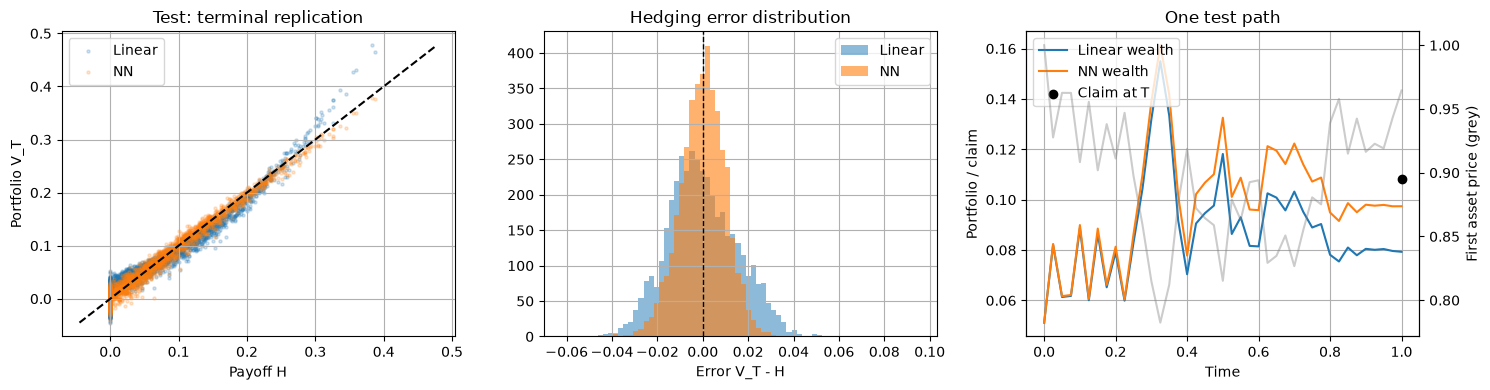

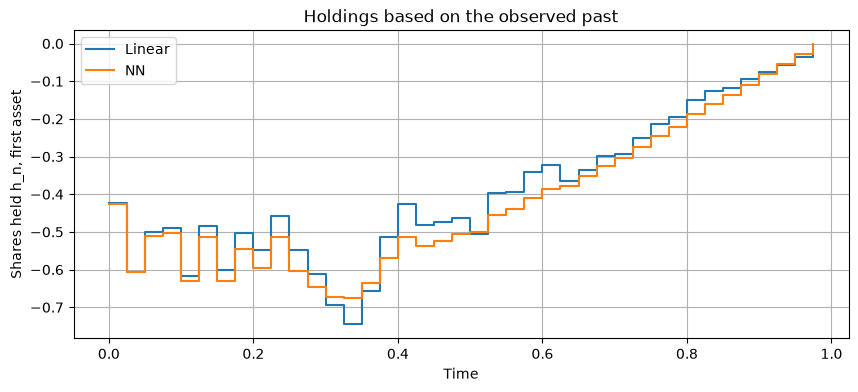

In [10]:
def error_metrics(error):
    return {'MSE': error.square().mean().item(),
            'RMSE': error.square().mean().sqrt().item(),
            'MAE': error.abs().mean().item(),
            'Bias': error.mean().item()}

with torch.no_grad():
    V_test, h_test = portfolio(model, F_test, S_test)
    error = V_test[:, -1] - H_test
    V_linear_test, h_linear_test = linear_portfolio(linear_coefficients, F_test, S_test)
    linear_error = V_linear_test[:, -1] - H_test

hedged = error_metrics(error)
linear_metrics = error_metrics(linear_error)
print(f'{"Strategy":<18} {"MSE":>10} {"RMSE":>10} {"MAE":>10} {"Bias":>10}')
for name, metrics in [('Linear signature', linear_metrics), ('Signature + NN', hedged)]:
    print(f'{name:<18} ' + ' '.join(f'{x:10.6f}' for x in metrics.values()))
print(f'Fixed initial capital (Q price): {model.capital.item():.5f}')
print(f'Physical-measure test mean payoff (not a price): {H_test.mean():.5f} ± {1.96 * H_test.std() / math.sqrt(n_test):.5f} (approx. 95% MC CI)')
print(f'95th percentile of |error|: linear {linear_error.abs().quantile(0.95):.5f}, '
      f'NN {error.abs().quantile(0.95):.5f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(H_test.numpy(), V_linear_test[:, -1].numpy(), s=5, alpha=0.2, label='Linear')
axes[0].scatter(H_test.numpy(), V_test[:, -1].numpy(), s=5, alpha=0.2, label='NN')
axes[0].legend()
lo = min(H_test.min().item(), V_test[:, -1].min().item(), V_linear_test[:, -1].min().item())
hi = max(H_test.max().item(), V_test[:, -1].max().item(), V_linear_test[:, -1].max().item())
axes[0].plot([lo, hi], [lo, hi], 'k--')
axes[0].set(xlabel='Payoff H', ylabel='Portfolio V_T', title='Test: terminal replication')
bins = np.histogram_bin_edges(torch.cat([linear_error, error]).numpy(), bins=70)
axes[1].hist(linear_error.numpy(), bins=bins, alpha=0.5, label='Linear')
axes[1].hist(error.numpy(), bins=bins, alpha=0.6, label='NN')
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set(xlabel='Error V_T - H', title='Hedging error distribution')
axes[1].legend()
example = 0  # first test path, without selecting a favorable outcome
axes[2].plot(times, V_linear_test[example], label='Linear wealth')
axes[2].plot(times, V_test[example], label='NN wealth')
axes[2].scatter([T], [H_test[example]], color='black', label='Claim at T', zorder=5)
axes[2].set(xlabel='Time', ylabel='Portfolio / claim', title='One test path')
axes[2].legend(loc='upper left')
other_axis = axes[2].twinx()
other_axis.plot(times, S_test[example, :, 0], color='grey', alpha=0.4)
other_axis.set_ylabel('First asset price (grey)')
other_axis.grid(False)
fig.tight_layout(); plt.show()

plt.step(times[:-1], h_linear_test[example, :, 0], where='post', label='Linear')
plt.step(times[:-1], h_test[example, :, 0], where='post', label='NN')
plt.legend()
plt.xlabel('Time'); plt.ylabel('Shares held h_n, first asset')
plt.title('Holdings based on the observed past'); plt.show()

## 8. Interpretation

- Terminal wealth close to the claim and errors concentrated around zero indicate effective replication.
- Residual errors reflect discrete trading, signature truncation, imperfect optimization and Monte Carlo pricing uncertainty.
- Fresh simulation avoids repeatedly fitting a finite training sample; it does not remove model or approximation error.
- Signature dimension grows exponentially with depth and the number of assets.
- Training and testing use physical drift $\mu$; pricing uses risk-neutral drift $r$. Volatility and correlation are the same under both measures.
- The experiment assumes no transaction costs and equal lending and borrowing rates.
- The linear-versus-neural comparison measures the benefit of a nonlinear trading rule at the chosen signature degree. It does not establish universality or superiority over other state representations.
- Bermudan exercise would require an exercise policy, a payoff at each exercise date, and trading stopped at the exercise time.